<a href="https://colab.research.google.com/github/karenl7/engr550-internal/blob/main/Module_3_HW_log_barrier_cvxpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Robot charging problem with `cvxpy`

In [56]:
# import packages
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
# -----------------------------
#  Problem parameters
# -----------------------------
NUM_ROBOTS              = 4   # number of robots
NUM_TIMES               = 8   # number of time slots
cost_per_hour           = np.array([0.18, 0.16, 0.14, 0.13, 0.15, 0.20, 0.24, 0.22])    # $/kWh
required_kWh_per_robot  = np.array([12.0, 10.0, 9.0, 11.0])                             # kWh required by morning
max_kWph_per_robot      = np.array([3.0, 2.5, 2.0, 3.5])                                # kWh per hour per robot
max_kW_per_hour         = np.array([8.0, 8.0, 7.0, 7.0, 7.0, 6.0, 6.0, 6.0])            # station cap per hour

def construct_problem_and_solve(objective_norm, gamma):
    """
    Construct and solve the optimization problem with the given objective and constraints.
    Returns the optimal charging schedule and the optimal value of the objective function.
    Arguments:
    - objective_norm: 'L1' or 'L2', indicating which smoothness penalty to use in the objective function.
    - gamma: the weight of the smoothness penalty in the objective function.

    Returns:
    - x.value: the optimal charging schedule (N x T matrix)
    - prob.value: the optimal value of the objective function
    - energy_cost: the total energy cost (without smoothness penalty)
    - prob: the cvxpy Problem object (for further analysis if needed)
    """

    # -----------------------------------
    #  Problem variables
    # -----------------------------------
    # Create a CVXPY variable named x with one row per robot and one column
    # per time slot. Each entry represents charging energy in that hour.
    # Use N and T to determine its shape.
    # Replace the placeholder below with your implementation.
    x = cp.Variable((NUM_ROBOTS, NUM_TIMES))

    # -----------------------------
    # Objective
    # Minimize energy cost + gamma * smoothness penalty
    # -----------------------------
    # Build a scalar CVXPY expression named energy_cost: first total the
    # charging energy across robots in each slot, then weight it by c.
    # cost = sum((cost_per_hour * kilowatts going at that hour), for every hour)
    energy_cost = cp.Variable()
    energy_cost_weight = 4.0
    energy_cost = sum(cp.sum(x[:, hour]) * cost_for_this_hour for hour, cost_for_this_hour in enumerate(cost_per_hour))

    # Form the change in each robot's charging energy between consecutive
    # slots. Penalize these changes using either the sum of absolute values
    # (L1) or the sum of squared values (the L2 penalty used in this exercise).
    # Use objective_norm to select the penalty and gamma to weight it.
    assert objective_norm == 'L1' or objective_norm == 'L2', ("unimplemented objective_norm", objective_norm)
    changes = [[]] * NUM_ROBOTS
    for robot in range(NUM_ROBOTS):
        for time in range(NUM_TIMES - 1):
            change = x[robot, time] - x[robot, time + 1]
            changes[robot].append(change)

    spikiness_cost = cp.Variable()
    if objective_norm == 'L1':
        spikiness_cost = sum(cp.norm1(cp.hstack(charge_changes)) for charge_changes in changes)
    else:
        spikiness_cost = sum(cp.sum_squares(cp.hstack(charge_changes)) for charge_changes in changes)

    # Store the minimization objective in a variable named objective.
    # The loop below calls this function for every norm/gamma combination;
    # use the arguments here instead of hard-coding separate objectives.
    # Helpful CVXPY functions: sum, multiply, norm1, sum_squares, Minimize.
    objective = cp.Minimize(energy_cost * energy_cost_weight + spikiness_cost * gamma)

    # -----------------------------
    # Constraints
    # -----------------------------
    # TODO: define the constraints here.
    # Store CVXPY constraints in a list named constraints. Enforce:
    # - Nonnegative charging energy for every robot and time slot.
    # - At least E[i] total energy for robot i over the entire night.
    # - Each robot's hourly charging limit, given by r_max.
    # - The shared station's hourly capacity, given by P_max.
    # Think about which axis to sum over for robot totals versus slot totals.
    # Check array shapes when comparing x to a per-robot vector: reshaping
    # that vector as a column can help apply each limit across all slots.
    # Replace the placeholder below with your implementation.
    constraints = []
    constraints.extend([cp.sum(x[robot, :]) >= charge for robot, charge in enumerate(required_kWh_per_robot)])
    constraints.extend([cp.min(x[robot, :]) >= 0 for robot, max_charge_per_hour in enumerate(max_kWph_per_robot)])
    constraints.extend([cp.max(x[robot, :]) <= max_charge_per_hour for robot, max_charge_per_hour in enumerate(max_kWph_per_robot)])
    constraints.extend([cp.sum(x[:, time]) <= max_station_charge_per_hour for time, max_station_charge_per_hour in enumerate(max_kW_per_hour)])

    prob = cp.Problem(objective, constraints)
    prob.solve()
    energy_cost = energy_cost.value
    return x.value, prob.value, energy_cost, prob


def plot_charging_schedule(x_sol, title):
    """
    Plot the charging schedule for each robot over time.
    """

    for i in range(NUM_ROBOTS):
        plt.plot(range(NUM_TIMES), x_sol[i, :], marker='o', label=f'Robot {i+1}')
        plt.hlines(max_kWph_per_robot[i], 0, NUM_TIMES-1, color=f"C{i}", linestyles='dashed')
    plt.plot(np.sum(x_sol, axis=0), marker='o', color='black', label='Total')
    plt.plot(range(NUM_TIMES), max_kW_per_hour, color='black', linestyle='dotted', label='Station Cap')
    plt.title(title)
    plt.xlabel('Time Slot')
    plt.ylabel('Charging Energy (kWh)')
    plt.xticks(range(NUM_TIMES))
    # plt.ylim(0, max(r_max) + 1)
    plt.grid()
    plt.legend(ncol=2)
    # plt.show()

In [58]:
# solve problem with different objective norms and gammas
objective_norms = ['L1', 'L2']
gammas = [0.1, 0.9]


checking constraints for objective norm: L1 and gamma: 0.1
[np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_]
checking constraints for objective norm: L1 and gamma: 0.9
[np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_]
checking constraints for objective norm: L2 and gamma: 0.1
[np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.False_, np.True_, np.True_, np.True_, np.True_, np.True_]
checking constraints for objective norm: L2 and gamma: 0.9
[np.False_, np.False_, np.False_, np.False_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.True_, np.Tr

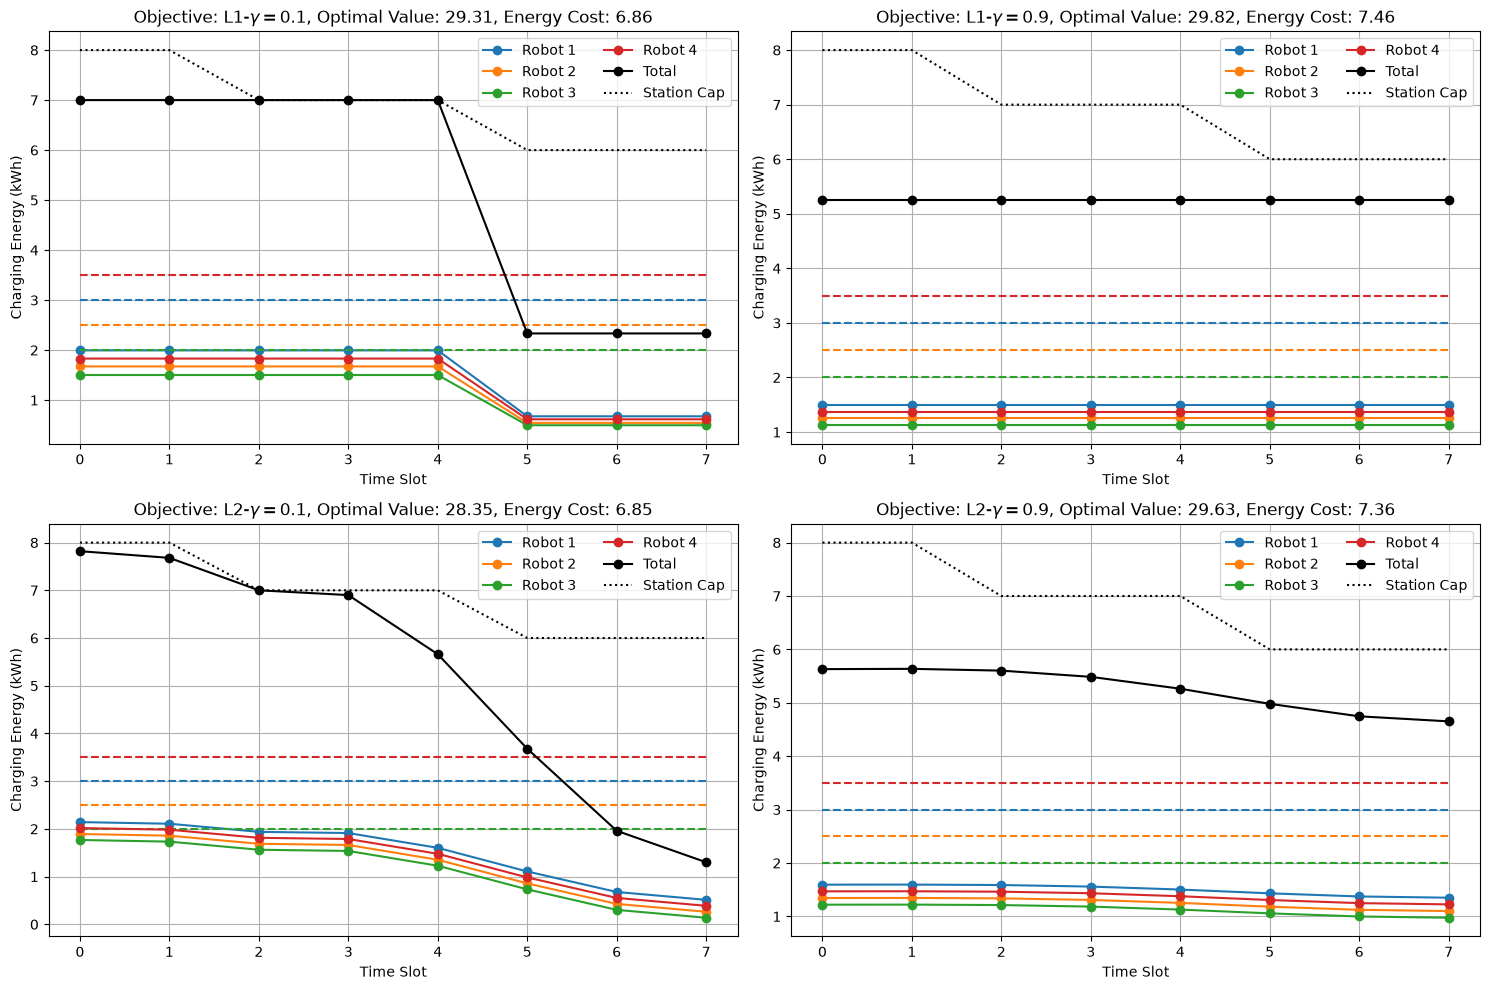

In [59]:
# plot results for each combination of objective norm and gamma

plt.figure(figsize=(15, 10))
k = 0
for on in objective_norms:
    for gamma in gammas:
        k += 1
        plt.subplot(2, 2, k)
        x_sol, obj_val, energy_cost, prob = construct_problem_and_solve(on, gamma)
        print("checking constraints for objective norm:", on, "and gamma:", gamma)
        print([constraint.value() for constraint in prob.constraints])
        name = f'{on}-$\\gamma={gamma}$'
        plot_charging_schedule(x_sol, f'Objective: {name}, Optimal Value: {obj_val:.2f}, Energy Cost: {energy_cost:.2f}')
    plt.tight_layout()